# ocr-labins-index.ipynb

This file runs OCR on the front pages of the LABINS volume index PDFs in `data/labins-index/` and stops at the first page where OCR confidence degrades. The typed index pages come first, and the first degraded page is the handwritten index page that follows them. Run on a GPU runtime in Google Colab (preferably T4 GPU or higher).

This pilot runs on volumes 4, 9 and 80. Confident pages are stored in `.txt` and `.json` formats in `data/labins-index/ocr/`, along with a `_cutoff.json` per volume holding the page statistics and the detected cutoff. The last cell shows the last confident page next to the first degraded page for each volume, to check that the cutoff lands where it should.

In [2]:
# setup
CUDA_TAG = "cu126"
import glob, shutil, sysconfig, importlib.util
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

# set dir
DATA_DIR = "/content/drive/MyDrive/armed-occupation-act/data"
WHEELS = "/content/drive/MyDrive/armed-occupation-act/wheels"

# cache paddle wheel
if not glob.glob(f"{WHEELS}/paddlepaddle_gpu*.whl"):
  print("downloading paddle wheel")
  !pip download -q --no-deps paddlepaddle-gpu -i https://www.paddlepaddle.org.cn/packages/stable/{CUDA_TAG}/ -d {WHEELS}

# install
if importlib.util.find_spec("paddle") is None:
  print("installing paddle")
  !pip -q install --find-links {WHEELS} paddlepaddle-gpu
  !pip -q install paddleocr pymupdf

# remove torch
if importlib.util.find_spec("torch") is not None:
  print("removing torch")
  !pip -q uninstall -y torch torchvision torchaudio
  site = Path(sysconfig.get_paths()["purelib"])
  for pat in ["torch", "torch-*", "torchgen", "functorch"]:   # pip leaves stubs behind
        for p in site.glob(pat):
            shutil.rmtree(p, ignore_errors=True)
print("torch:", importlib.util.find_spec("torch"))   # should be None

Mounted at /content/drive
installing paddle
removing torch
torch: None


In [3]:
# verify CUDA
!nvidia-smi
import paddle
print("compiled with CUDA:", paddle.device.is_compiled_with_cuda())
print("device:", paddle.device.get_device())
paddle.utils.run_check()
assert paddle.device.is_compiled_with_cuda() and "gpu" in paddle.device.get_device(), \
    "Paddle is not using the GPU!"

Wed Nov 11 05:33:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


compiled with CUDA: True
device: gpu:0
Running verify PaddlePaddle program ... 


/usr/local/lib/python3.13/dist-packages/paddle/pir/math_op_patch.py:241: UserWarning: Tensor do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.


In [5]:
# imports
import os
os.environ.update({"GLOG_minloglevel": "3", "PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK": "True"})
import json, logging, warnings
logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")

from pathlib import Path
import pymupdf
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from paddleocr import PaddleOCR

# set dir
DATA_DIR = "/content/drive/MyDrive/armed-occupation-act/data"
IN_DIR = Path(DATA_DIR)
OUT_DIR = IN_DIR / "labins-ocr"
OUT_DIR.mkdir(exist_ok=True)

# config
VOLS = [4, 9, 80]
LONG_SIDE = 4000     # render size in px, set from page size so dpi is not assumed
MAX_PAGES = 15       # stop here even if no degraded page found
LINE_MIN = 0.90      # a line is confident at or above this score
MEAN_MIN = 0.90      # page is degraded if mean line score is below this
SHARE_MIN = 0.80     # page is degraded if share of confident lines is below this

# helpers
def save(path, text):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(text, encoding="utf-8")
    tmp.replace(path)                                    # atomic checkpoint

def render(doc, i):
    zoom = LONG_SIDE / max(doc[i].rect.width, doc[i].rect.height)
    pix = doc[i].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
    return np.array(Image.frombytes("RGB", [pix.width, pix.height], pix.samples))

def to_record(i, img, r):
    boxes = r["rec_boxes"] if "rec_boxes" in r else [[*np.min(p, 0).tolist(), *np.max(p, 0).tolist()] for p in r["rec_polys"]]
    h, w = img.shape[:2]
    lines = [{"text": t, "score": round(float(s), 4), "box": np.asarray(b).tolist()}   # box is x0,y0,x1,y1 in pixels
             for t, s, b in zip(r["rec_texts"], r["rec_scores"], boxes)]
    return {"page": i + 1, "width": w, "height": h, "lines": lines}

def page_stats(r):
    s = np.asarray(r["rec_scores"], dtype=float)
    if len(s) == 0:
        return {"n_lines": 0, "mean": 0.0, "share": 0.0}
    return {"n_lines": int(len(s)), "mean": round(float(s.mean()), 4), "share": round(float((s >= LINE_MIN).mean()), 4)}

def is_good(st):
    return st["n_lines"] > 0 and st["mean"] >= MEAN_MIN and st["share"] >= SHARE_MIN   # empty page counts as degraded

# model
ocr = PaddleOCR(device="gpu",
                use_doc_orientation_classify=False,
                use_doc_unwarping=False,
                use_textline_orientation=False)

# ocr until degraded page
for v in VOLS:
    name = f"vol{v:03d}"
    cut_file = OUT_DIR / f"{name}_cutoff.json"
    if cut_file.exists():
        print(name, "already done")
        continue
    doc = pymupdf.open(IN_DIR / f"{name}.pdf")
    txt_dir = OUT_DIR / f"{name}_pages"
    json_dir = OUT_DIR / f"{name}_json"
    txt_dir.mkdir(exist_ok=True)
    json_dir.mkdir(exist_ok=True)

    stats, n_good, first_bad = [], 0, None
    for i in tqdm(range(min(MAX_PAGES, len(doc))), desc=name, unit="page"):
        img = render(doc, i)
        r = next(iter(ocr.predict(img)))                 # one page at a time so we can stop early
        st = {"page": i + 1, **page_stats(r)}
        stats.append(st)
        if not is_good(st):
            first_bad = i + 1
            break
        save(txt_dir / f"{i+1:04d}.txt", "\n".join(r["rec_texts"]))
        save(json_dir / f"{i+1:04d}.json", json.dumps(to_record(i, img, r), ensure_ascii=False))
        n_good += 1

    # merge confident pages
    (OUT_DIR / f"{name}.txt").write_text(
        "".join(f"\n\n===== PAGE {i+1} =====\n" + (txt_dir / f"{i+1:04d}.txt").read_text(encoding="utf-8")
                for i in range(n_good)), encoding="utf-8")
    (OUT_DIR / f"{name}.json").write_text(
        json.dumps([json.loads((json_dir / f"{i+1:04d}.json").read_text(encoding="utf-8")) for i in range(n_good)],
                   ensure_ascii=False), encoding="utf-8")

    # cutoff record
    save(cut_file, json.dumps({"vol": v, "n_pages": len(doc), "n_good": n_good, "first_degraded": first_bad,
                               "line_min": LINE_MIN, "mean_min": MEAN_MIN, "share_min": SHARE_MIN, "stats": stats}))
    print(name, f"{n_good} confident pages, first degraded page: {first_bad}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

vol004:   0%|          | 0/15 [00:00<?, ?page/s]

vol004 8 confident pages, first degraded page: 9


vol009:   0%|          | 0/14 [00:00<?, ?page/s]

vol009 0 confident pages, first degraded page: 1


vol080:   0%|          | 0/15 [00:00<?, ?page/s]

vol080 3 confident pages, first degraded page: 4


vol 4: 38 pages, 8 confident, first degraded: 9


,n_lines,mean,share
page,,,
1,71,0.9935,0.9859
2,79,0.9952,1.0000
3,41,0.9957,1.0000
4,70,0.9859,0.9571
5,71,0.9935,0.9859
6,79,0.9952,1.0000
7,41,0.9957,1.0000
8,70,0.9859,0.9571
9,96,0.9154,0.7604


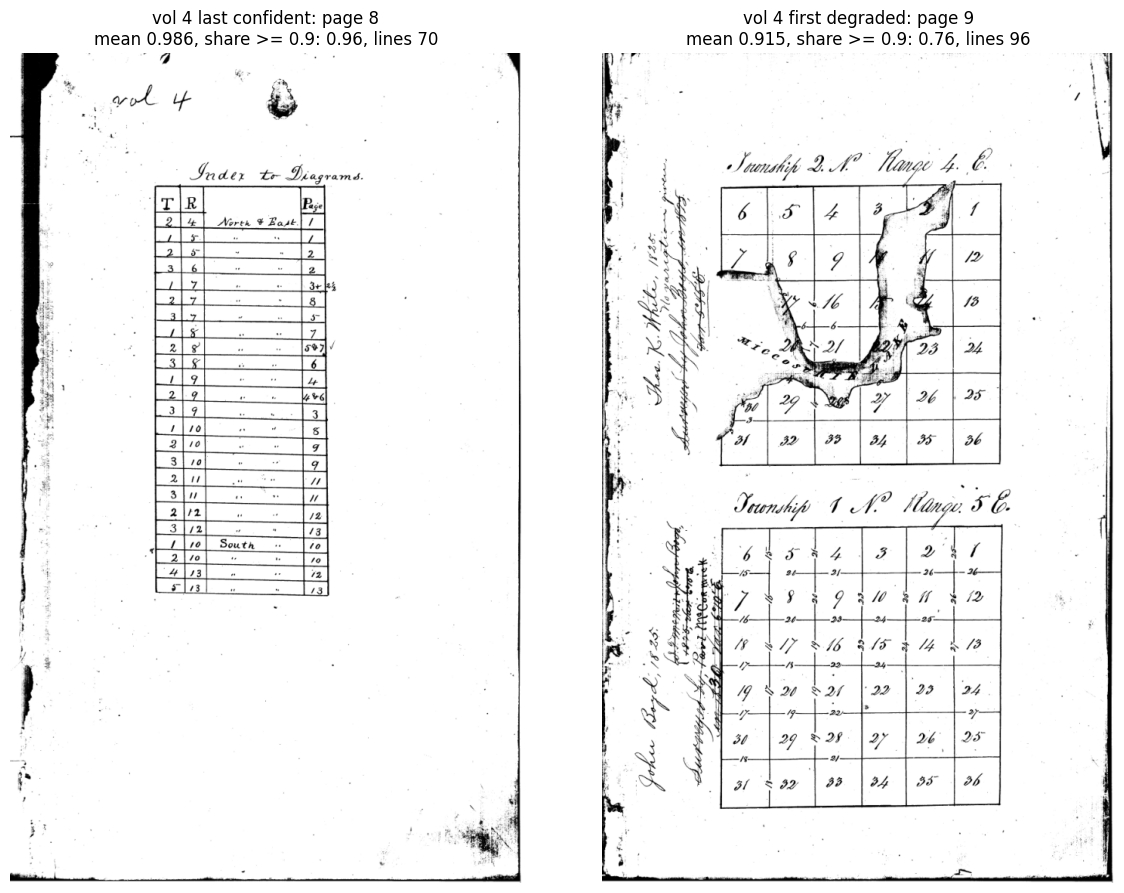

vol 9: 14 pages, 0 confident, first degraded: 1


,n_lines,mean,share
page,,,
1,3,0.6546,0.6667


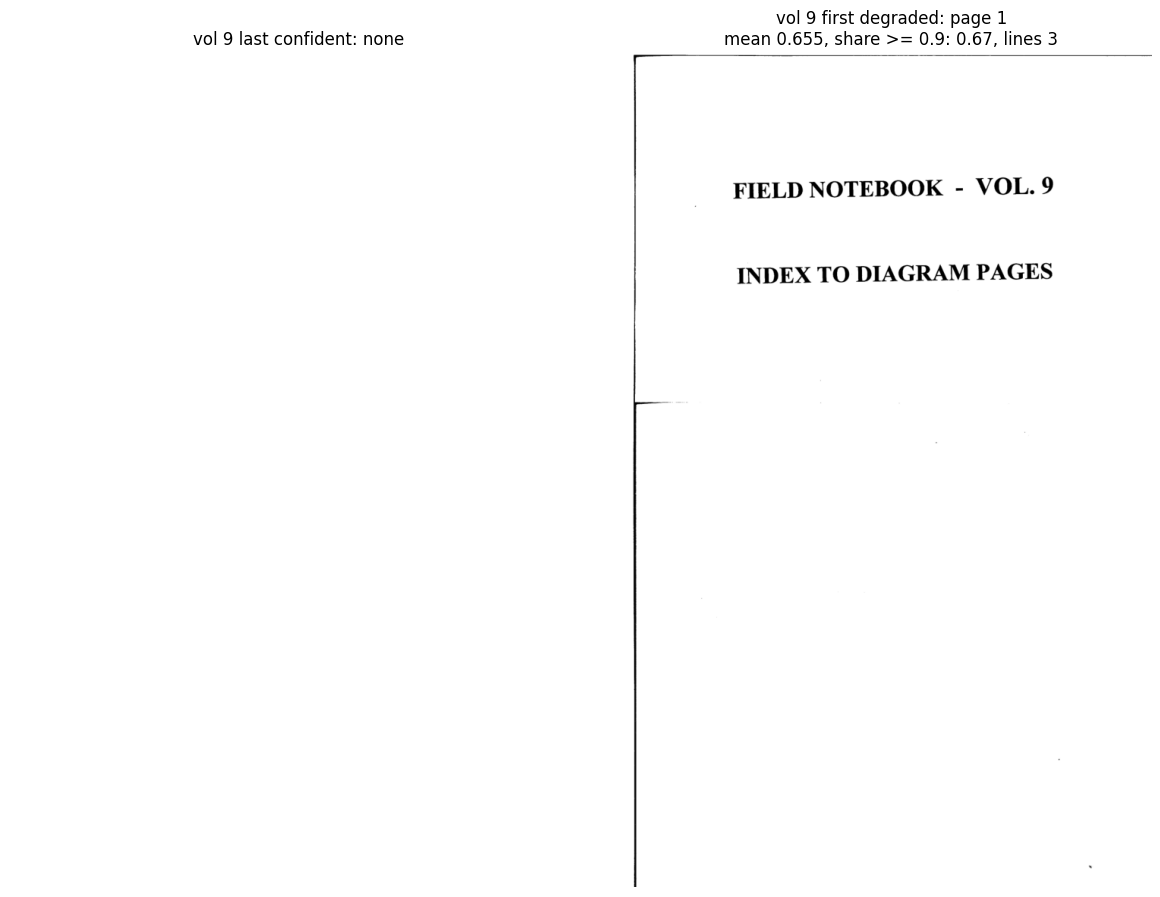

vol 80: 47 pages, 3 confident, first degraded: 4


,n_lines,mean,share
page,,,
1,67,0.9897,1.0000
2,77,0.9937,1.0000
3,50,0.9952,1.0000
4,86,0.8166,0.5698


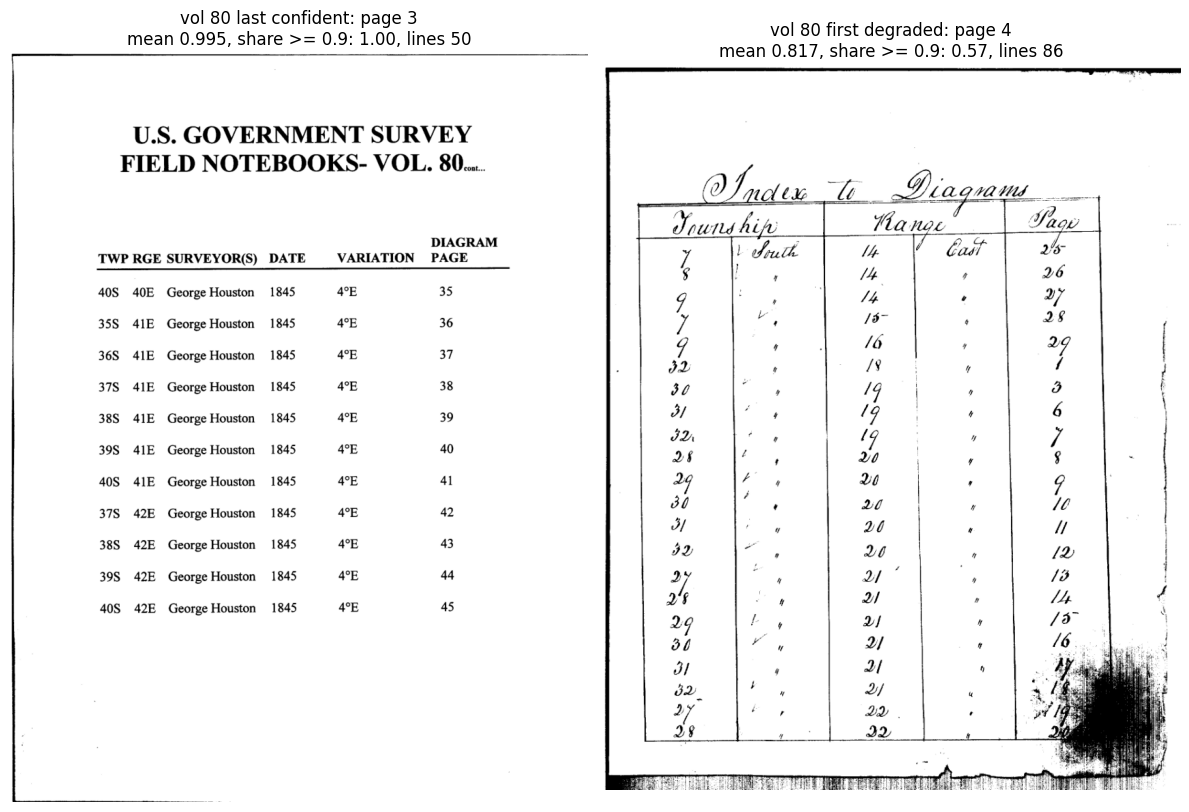

In [6]:
# setup
import json
import numpy as np
import pandas as pd
import pymupdf
import matplotlib.pyplot as plt
from pathlib import Path

# set dir
VOLS = [4, 9, 80]
SHOW_PX = 1100   # long side of displayed page in px

# page image
def page_img(doc, i):
    zoom = SHOW_PX / max(doc[i].rect.width, doc[i].rect.height)
    pix = doc[i].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom))
    return np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, 3)

# last confident vs first degraded
for v in VOLS:
    cut = json.loads((OUT_DIR / f"vol{v:03d}_cutoff.json").read_text())
    doc = pymupdf.open(IN_DIR / f"vol{v:03d}.pdf")
    st = pd.DataFrame(cut["stats"]).set_index("page")
    print(f"vol {v}: {cut['n_pages']} pages, {cut['n_good']} confident, first degraded: {cut['first_degraded']}")
    display(st)   # stats for every page examined
    fig, axes = plt.subplots(1, 2, figsize=(12, 9))
    for ax, (label, p) in zip(axes, [("last confident", cut["n_good"]), ("first degraded", cut["first_degraded"])]):
        ax.axis("off")
        if p:
            ax.imshow(page_img(doc, p - 1))
            ax.set_title(f"vol {v} {label}: page {p}\nmean {st.loc[p, 'mean']:.3f}, share >= {cut['line_min']}: {st.loc[p, 'share']:.2f}, lines {st.loc[p, 'n_lines']}")
        else:
            ax.set_title(f"vol {v} {label}: none")
    plt.tight_layout()
    plt.show()